In [1]:
import RST_cart.generate_plane_points as points
import RST_cart.DDA as DDA
import RST_cart.physical_module as physical_module
import numpy as np
import matplotlib.pyplot as plt

In [6]:
def cal_image(rho,pres,Te,R,wavelength,left_edge,right_edge,center,normal,width,resolution,absorption=True):
    if wavelength == 'radio':
        kappa_data, j_data = physical_module.cal_radio(rho,pres,Te)
    if wavelength == 'white_light':
        kappa_data, j_data = physical_module.cal_white_light(rho,R)
    else:
        kappa_data, j_data = physical_module.cal_euv(rho,pres,Te,wavelength,absorption)

    vc = DDA.VolumeContainer(kappa_data, j_data, left_edge, right_edge)
    
    plane_points = points.generate_plane_points(center, normal, width, resolution)
    
    image = DDA.integrate_plane_points(plane_points, normal, vc, max_t=width)

    return image

In [114]:
import numpy as np
import time

#cgs,the sample codes from sphere to cartesian is mentioned in 

#folder_path='/Users/xiaoxingyun/Desktop/jet_mhd/rad_test/'
#data=np.load(folder_path+'your_data')

rho=np.load('/Users/xiaoxingyun/Desktop/jet_mhd/rad_test/rho10.npy').T
Te=np.load('/Users/xiaoxingyun/Desktop/jet_mhd/rad_test/tem10.npy').T
pres=np.load('/Users/xiaoxingyun/Desktop/jet_mhd/rad_test/presure10.npy').T

rho = np.nan_to_num(rho, nan=0)
Te = np.nan_to_num(Te, nan=0)
pres = np.nan_to_num(pres, nan=0)

# Set the grid bounds and choose the wavelength/band
left_edge  = np.array([-3, -3, 0.11]) * 1e9
right_edge = np.array([3,3,12.11]) * 1e9

# If EUV, supply the numerical wavelength;  
# if radio or Thomson scatter, use the string 'radio' or 'white_light'
wavelength = 131

# EUV and radio are treated as optically thick by default; white_light is optically thin.  
# Set absorption = False to obtain optically thin EUV emission.
absorption = False

# If you select white_light you must provide an array of radial distances (R) for every grid cell;  
# otherwise keep R = np.zeros(rho.shape)
R = np.zeros(rho.shape)

# Choose the line of sight for synthetic imaging
center  = np.array([0,0,6.11]) * 1e9     # Plane centre
normal  = np.array([0,1,0])                    # Plane normal in use

# Define the foot‑points of rays in the image plane:  
#   • width       – physical width of the plane  
#   • resolution  – image resolution (resolution × resolution rays)
width       = 12 * 1e9
resolution  = 256*2


image = cal_image(rho,pres,Te,R,wavelength,left_edge,right_edge,center,normal,width,resolution,absorption)


/var/folders/lh/g6g6b1bs4kg77rhgy95s2xnm0000gn/T/ipykernel_65498/4287876463.py:3: RuntimeWarning: divide by zero encountered in log10
  im = ax.imshow(np.log10(image.reshape(resolution,resolution)),cmap='sdoaia171',vmax = 4.5,vmin=0)


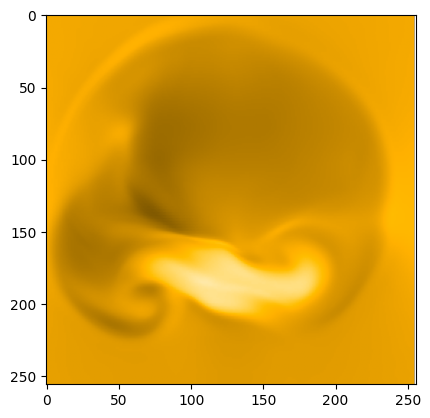

In [100]:
import sunpy.map
fig,ax = plt.subplots()
im = ax.imshow(np.log10(image.reshape(resolution,resolution)),cmap='sdoaia171',vmax = 4.5,vmin=0)

/var/folders/lh/g6g6b1bs4kg77rhgy95s2xnm0000gn/T/ipykernel_65498/2234475485.py:3: RuntimeWarning: divide by zero encountered in log10
  plt.imshow(np.log10(image.reshape(resolution,resolution)),cmap='sdoaia171',vmax = 4.5,vmin=0)


Text(0.5, 1.0, 't = 5 (Thin)')

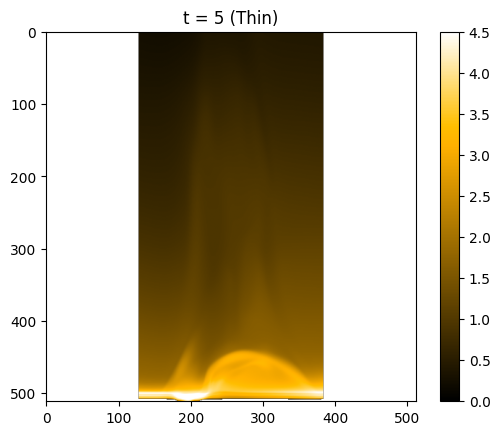

In [103]:
plt.imshow(np.log10(image.reshape(resolution,resolution)),cmap='sdoaia171',vmax = 4.5,vmin=0)
plt.colorbar()
plt.title('t = 5 (Thin)')

/var/folders/lh/g6g6b1bs4kg77rhgy95s2xnm0000gn/T/ipykernel_65498/236952008.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.imshow(np.log10(image.reshape(resolution,resolution))[0:500,:],cmap='sdoaia131',vmax = 2,vmin=0)


Text(0.5, 1.0, 't = 5 (Thin)')

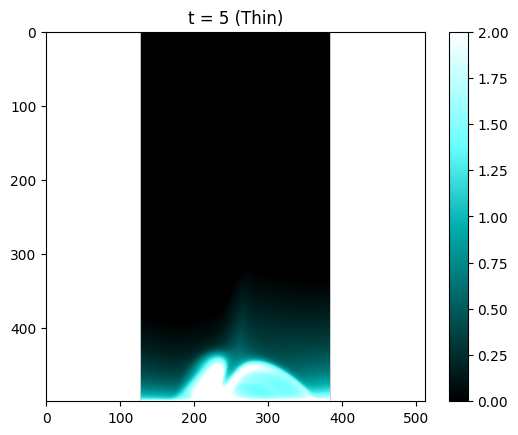

In [117]:
plt.imshow(np.log10(image.reshape(resolution,resolution))[0:500,:],cmap='sdoaia131',vmax = 2,vmin=0)
plt.colorbar()
plt.title('t = 5 (Thin)')

/var/folders/lh/g6g6b1bs4kg77rhgy95s2xnm0000gn/T/ipykernel_65498/3486116026.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.imshow(np.log10(image.reshape(resolution,resolution)),cmap='sdoaia304',vmax = 4.5,vmin=0)


Text(0.5, 1.0, 't = 30 (Thin)')

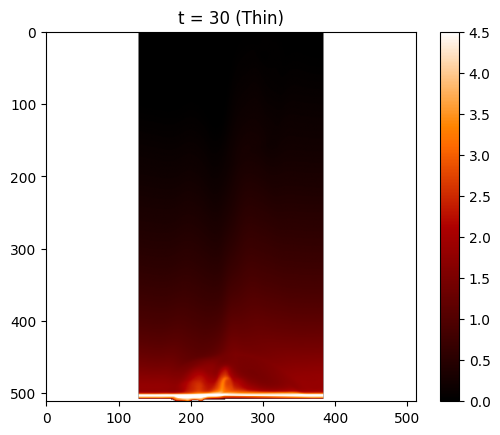

In [109]:
plt.imshow(np.log10(image.reshape(resolution,resolution)),cmap='sdoaia304',vmax = 4.5,vmin=0)
plt.colorbar()
plt.title('t = 30 (Thin)')

/var/folders/lh/g6g6b1bs4kg77rhgy95s2xnm0000gn/T/ipykernel_65498/2080456738.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.imshow(np.log10(image.reshape(resolution,resolution)),cmap='sdoaia131',vmax = 3,vmin=0)


Text(0.5, 1.0, 't = 30 (Thin)')

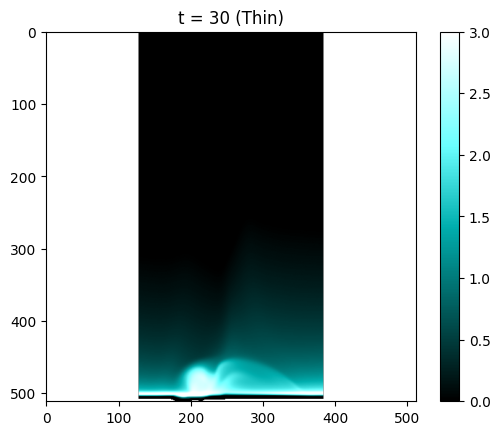

In [113]:
plt.imshow(np.log10(image.reshape(resolution,resolution)),cmap='sdoaia131',vmax = 3,vmin=0)
plt.colorbar()
plt.title('t = 30 (Thin)')